# 1 · Accumulation and the rate of profit

This notebook introduces the building blocks of MarxKapital: a *department* (a sector described by its constant capital `c`, variable capital `v` and rate of surplus value `e`), the classical two-department model, and the generalized model with N departments.

The code identifiers are Portuguese (`Department`, `profit_rate`, `simulate_Ndept`, …), and so is the library's console output. The prose here explains what each call does.

> **Note:** the first call of each function is slow because Julia compiles it. Later calls are fast.

In [1]:
# Run from notebooks/jupyter/. MarxKapital is loaded script-style, not as a package:
# the include does all the `using`s and defines everything in Main.
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, Random
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

## 1. A department

A `Department` holds the stock of constant capital `c`, variable capital (wages) `v`, the rate of surplus value `e = s/v`, and how surplus value is used: shares `σ_c` reinvested in constant capital, `σ_v` in variable capital, and `γ = 1 − σ_c − σ_v` consumed by capitalists. `δ` is the depreciation rate of `c`. The constructor checks these invariants and derives the organic composition `k = c/v`.

In [2]:
d = Department("Industry", c = 300.0, v = 100.0, e = 1.5, σ_c = 0.5, σ_v = 0.2, δ = 0.05)

Department("Industry": K=400.0, k=3.0, e=1.5, r=0.375)

The rate of profit is `r = s/(c + v) = e/(k + 1)`. The value of one period's product counts only the constant capital *used up* in the period (`δc`), not the whole stock: `W = δc + v + s`.

In [3]:
(k = d.k, s = surplus_value(d), r = profit_rate(d), K = total_capital(d), W = product_value(d), γ = d.γ)

(k = 3.0, s = 150.0, r = 0.375, K = 400.0, W = 265.0, γ = 0.3)

## 2. Organic composition against the rate of profit

At a given rate of surplus value, a higher organic composition means a lower rate of profit: this is the mechanism behind Marx's *law of the tendency of the rate of profit to fall*. A higher rate of exploitation `e` is one of the counteracting tendencies. Whether the rate of profit actually falls in a simulation depends on where the organic composition goes, as Section 4 shows.

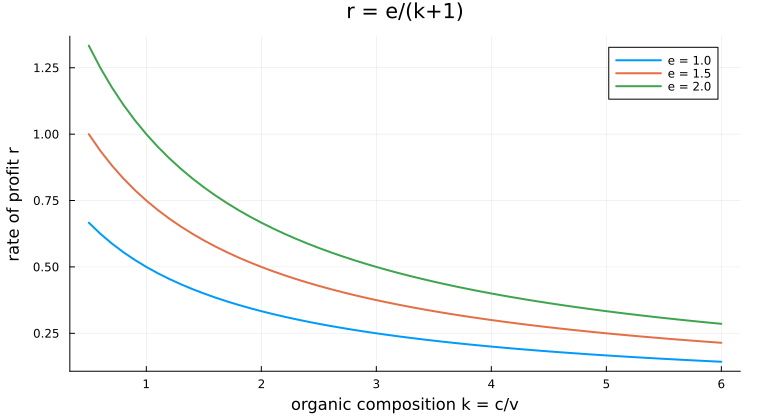

In [4]:
ks = 0.5:0.1:6.0
plot(xlabel = "organic composition k = c/v", ylabel = "rate of profit r",
     title = "r = e/(k+1)")
for e in (1.0, 1.5, 2.0)
    plot!(ks, [profit_rate(Department("x", c = 100k, v = 100.0, e = e)) for k in ks],
          lw = 2, label = "e = $e")
end
current()

## 3. The two-department model

Department I produces means of production and Department II consumer goods. `simulate_2dept` integrates the accumulation ODEs (state `[C₁, V₁, C₂, V₂]`) and returns the solution, the departments and the parameters.

In [5]:
sol, depts, p = simulate_2dept(T = 50.0)
depts

2-element Vector{Department}:
 Department("Means of Production": K=5000.0, k=4.0, e=1.0, r=0.2)
 Department("Consumer Goods": K=2500.0, k=4.0, e=1.0, r=0.2)

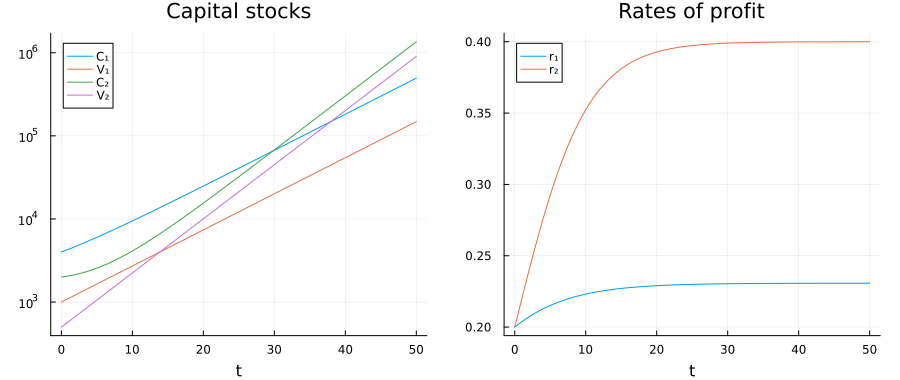

In [6]:
C1, V1, C2, V2 = (sol[i, :] for i in 1:4)
e = [d.e for d in depts]
r1 = e[1] ./ (C1 ./ V1 .+ 1)
r2 = e[2] ./ (C2 ./ V2 .+ 1)
plot(plot(sol.t, [C1 V1 C2 V2], label = ["C₁" "V₁" "C₂" "V₂"], yscale = :log10,
          title = "Capital stocks"),
     plot(sol.t, [r1 r2], label = ["r₁" "r₂"], title = "Rates of profit"),
     xlabel = "t", layout = (1, 2), size = (900, 380))

Marx's condition for expanded reproduction asks that Department I's demand for consumer goods equals Department II's demand for means of production: `V₁ + (1 − σ_c,₁)·S₁ = C₂ + σ_c,₂·S₂`, where `C` is the constant capital *used up* in the period. We check it at the end of the run:

In [7]:
δ = [d.δ for d in depts]
σ_c = [d.σ_c for d in depts]
eq = check_equilibrium_2dept(δ[1] * C1[end], V1[end], δ[2] * C2[end], V2[end], e..., σ_c...)
(; eq..., ratio = eq.lhs / eq.rhs)

(equilibrium = false, disequilibrium = -116348.81673219171, lhs = 222617.82867745357, rhs = 338966.6454096453, ratio = 0.6567543789106955)

The model does not impose the condition, so it is a diagnostic: in this run Department I's demand for consumer goods covers only about two thirds of Department II's demand for means of production.

The library also has a ready-made dashboard for this model:

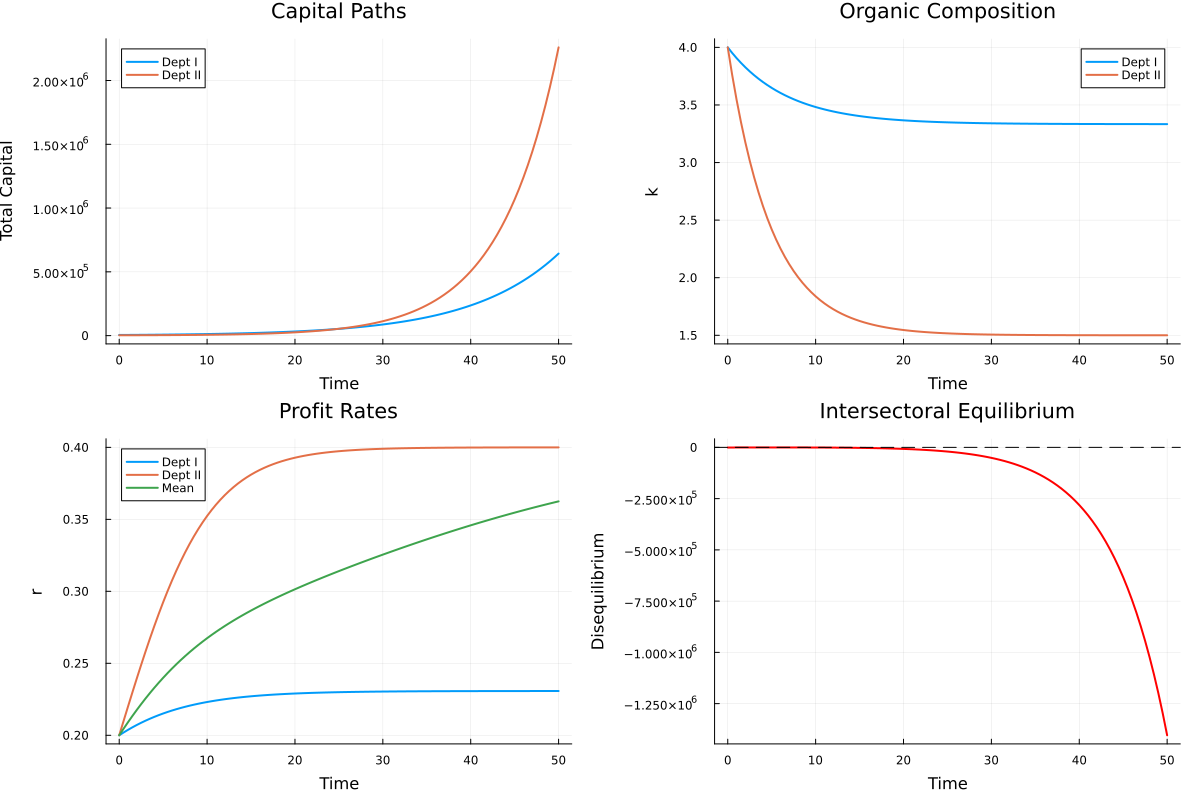

In [8]:
plot_2dept(sol, depts, p)

## 4. N departments

`create_departments(N)` draws plausible random departments whose organic composition rises with the sector index. In `simulate_Ndept`, `seed` only fixes the technical matrix `A`; the departments come from the global random number generator, so seed it first.

By default (`coupled = false`) the departments accumulate independently. Notebook 4 couples them through `A`.

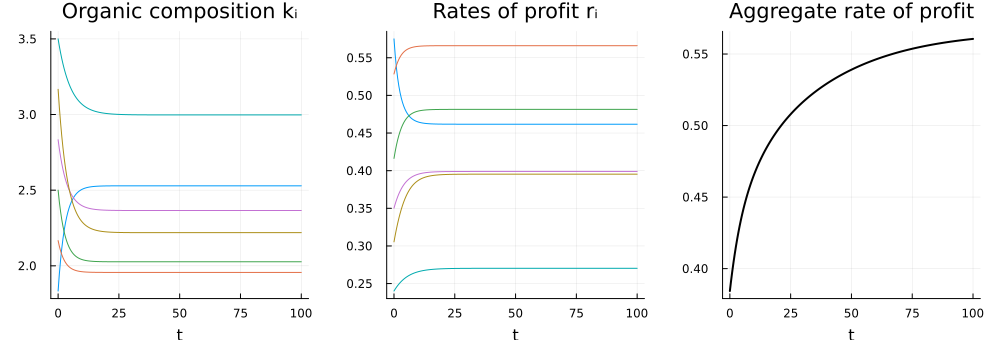

In [9]:
Random.seed!(42)
sol, depts, p = simulate_Ndept(6, T = 100.0, seed = 42)
k = compute_organic_compositions(sol)   # N × T
r = compute_profit_rates(sol, p.e)        # N × T
r̄ = compute_average_profit_rate(sol, p.e)   # aggregate ΣS / Σ(C+V)
plot(plot(sol.t, k', title = "Organic composition kᵢ", legend = false),
     plot(sol.t, r', title = "Rates of profit rᵢ", legend = false),
     plot(sol.t, r̄, title = "Aggregate rate of profit", legend = false, lw = 2, color = :black),
     xlabel = "t", layout = (1, 3), size = (1000, 340))

Organic compositions do not rise without limit. Each sector's `k` converges to a level set by how it splits accumulated surplus value between `C` and `V`, net of depreciation, so each sectoral rate of profit settles too. Whether it falls depends on whether that level is above the starting one: in this run most compositions fall, so most profit rates rise. The aggregate rate keeps rising after the sectoral rates have settled, because the sectors grow at different rates and their weights keep changing.

The spread of sectoral profit rates over time (`analyze_convergence`). Without capital mobility, nothing equalizes them.

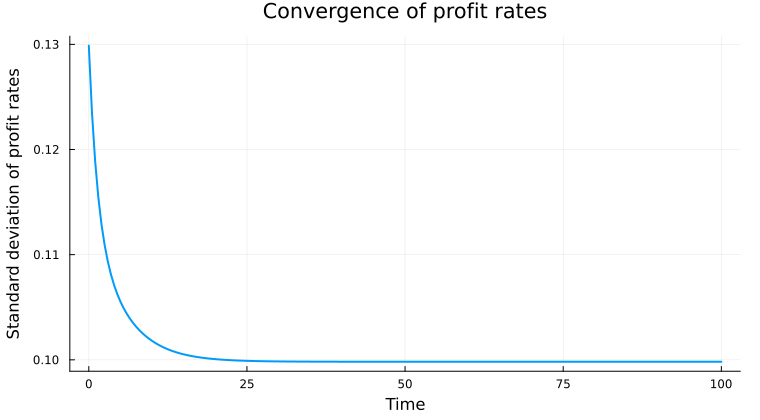

In [10]:
analyze_convergence(sol, depts, p)

## 5. A counteracting tendency: raising the rate of exploitation

`simulate_Ndept_custom` runs the model from given departments. We rerun the same economy with every rate of surplus value raised by 30% and compare the aggregate rate of profit.

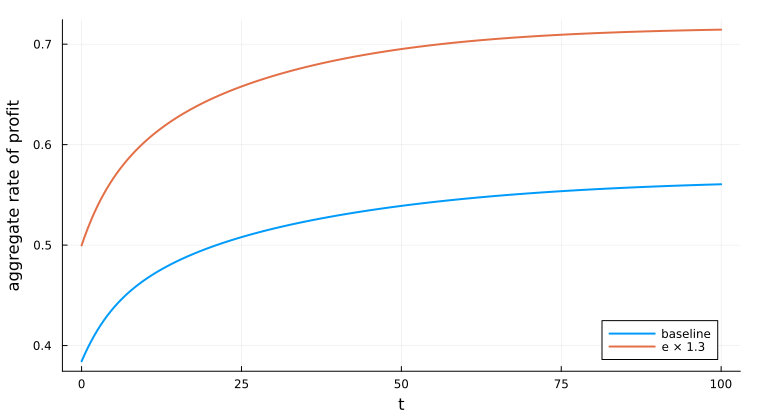

In [11]:
more_exploitation = [Department(d.name, c = d.c, v = d.v, e = 1.3d.e, σ_c = d.σ_c,
                                σ_v = d.σ_v, δ = d.δ) for d in depts]
sol2, _, p2 = simulate_Ndept_custom(more_exploitation, T = 100.0, seed = 42)
plot(sol.t, r̄, lw = 2, label = "baseline")
plot!(sol2.t, compute_average_profit_rate(sol2, p2.e), lw = 2, label = "e × 1.3",
      xlabel = "t", ylabel = "aggregate rate of profit")